# Lab Sheet 5: SIFT and HOG Feature Descriptors

**Syllabus Topic:** Utilization of SIFT and HOG features for image analysis

This single Jupyter Notebook implements all 10 questions from the lab sheet.

### Image selection
This notebook is designed for **Google Colab-style image selection**.

Each question uses:
```python
uploaded = files.upload()
```

After you select an image, the code saves it using the uploaded filename and uses that filename as the `image_path`. For questions needing two or more images, upload all required images in the same file chooser. For questions requiring two or more images, the upload widget accepts multiple files.

### Requirements
```bash
pip install opencv-contrib-python scikit-image scikit-learn matplotlib pandas ipywidgets
```

> **Note:** SIFT is included in modern OpenCV builds. If `cv2.SIFT_create()` is unavailable, install `opencv-contrib-python`.


In [3]:
pip install opencv-contrib-python scikit-image scikit-learn matplotlib pandas ipywidgets

In [4]:
# =========================
# 0. Imports and utilities
# =========================
import io
import os
import time
import math
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from skimage.feature import hog

# Google Colab upload
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 12


# ---------- Colab-style image upload ----------
def upload_one_image():
    """
    Opens the Google Colab file chooser and returns the uploaded filename.
    """
    if not IN_COLAB:
        print("This upload method is designed for Google Colab.")
        print("If you are using Jupyter locally, replace files.upload() with a local path.")

    uploaded = files.upload()

    image_path = None
    for filename in uploaded.keys():
        with open(filename, "wb") as f:
            f.write(uploaded[filename])
        print(f"Uploaded file: {filename}")
        image_path = filename
        break

    if image_path is None:
        raise ValueError("No image was uploaded.")

    if not os.path.exists(image_path):
        raise FileNotFoundError(f"Uploaded file not found at {image_path}.")

    image = cv2.imread(image_path)
    if image is None:
        raise ValueError(
            f"Could not load image from {image_path}. "
            "The file may be corrupted or not a valid image."
        )

    return image_path, image


def upload_multiple_images(min_files=2):
    """
    Opens the Google Colab file chooser and returns all uploaded image paths/images.
    """
    uploaded = files.upload()

    image_paths = []
    images = []

    for filename in uploaded.keys():
        with open(filename, "wb") as f:
            f.write(uploaded[filename])

        print(f"Uploaded file: {filename}")

        image = cv2.imread(filename)
        if image is not None:
            image_paths.append(filename)
            images.append(image)
        else:
            print(f"Warning: Could not load {filename}; skipping it.")

    if len(images) < min_files:
        raise ValueError(f"Please upload at least {min_files} valid image(s).")

    return image_paths, images


# ---------- General image helpers ----------
def show_image(img, title="", figsize=(10, 6), bgr=True, cmap=None):
    plt.figure(figsize=figsize)
    if len(img.shape) == 2:
        plt.imshow(img, cmap=cmap or "gray")
    else:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if bgr else img)
    plt.title(title)
    plt.axis("off")
    plt.show()


def to_gray(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if len(img.shape) == 3 else img


def ensure_gray_size(img, size=(128, 128)):
    return cv2.resize(to_gray(img), size, interpolation=cv2.INTER_AREA)


# ---------- SIFT ----------
def create_sift():
    if not hasattr(cv2, "SIFT_create"):
        raise RuntimeError(
            "SIFT is unavailable. Install opencv-contrib-python or use a "
            "recent OpenCV version."
        )
    return cv2.SIFT_create()


def sift_features(img):
    sift = create_sift()
    gray = to_gray(img)
    keypoints, descriptors = sift.detectAndCompute(gray, None)
    return keypoints, descriptors


# ---------- SIFT matching ----------
def ratio_match(desc1, desc2, ratio=0.75):
    if desc1 is None or desc2 is None:
        return []
    if len(desc1) < 2 or len(desc2) < 2:
        return []

    bf = cv2.BFMatcher()
    knn = bf.knnMatch(desc1, desc2, k=2)
    good = [m for m, n in knn if m.distance < ratio * n.distance]
    return good


# ---------- HOG ----------
def hog_descriptor(
    img,
    image_size=(128, 128),
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2)
):
    gray = ensure_gray_size(img, image_size)
    return hog(
        gray,
        orientations=orientations,
        pixels_per_cell=pixels_per_cell,
        cells_per_block=cells_per_block,
        block_norm="L2-Hys",
        feature_vector=True
    )


def hog_visualization(
    img,
    image_size=(128, 128),
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2)
):
    gray = ensure_gray_size(img, image_size)

    feature, hog_img = hog(
        gray,
        orientations=orientations,
        pixels_per_cell=pixels_per_cell,
        cells_per_block=cells_per_block,
        block_norm="L2-Hys",
        visualize=True,
        feature_vector=True
    )
    return feature, hog_img


print("Libraries loaded successfully.")
print("OpenCV version:", cv2.__version__)
print("Colab upload mode:", IN_COLAB)


Libraries loaded successfully.
OpenCV version: 5.0.0
Colab upload mode: True


## Q1. Build a keypoint detector and visualizer using SIFT
Display detected keypoints with their scale and orientation.

Saving image_9c5ab6c3.jpg to image_9c5ab6c3 (1).jpg
Uploaded file: image_9c5ab6c3 (1).jpg
Image: image_9c5ab6c3 (1).jpg
Total SIFT keypoints detected: 1945


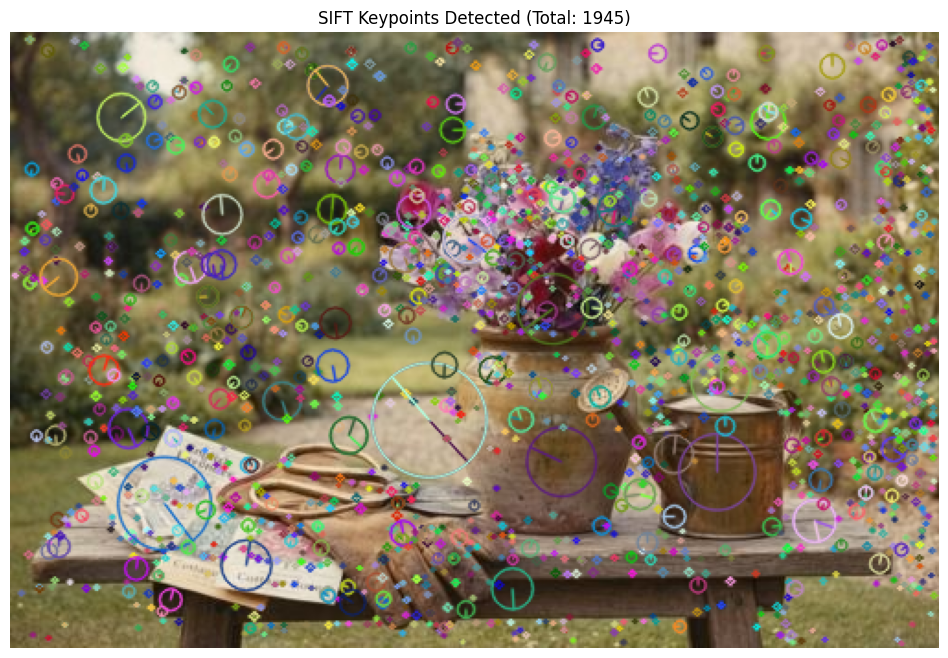

In [5]:
# Q1 - Upload one image
import io
uploaded = files.upload()

for filename in uploaded.keys():
    with open(filename, 'wb') as f:
        f.write(uploaded[filename])
    print(f'Uploaded file: {filename}')
    image_path = filename
    break

if not os.path.exists(image_path):
    print(f"Error: Uploaded file not found at {image_path}.")
else:
    image = cv2.imread(image_path)

    if image is None:
        print(f"Error: Could not load image from {image_path}.")
    else:
        gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        sift = cv2.SIFT_create()
        keypoints, descriptors = sift.detectAndCompute(gray_image, None)

        image_with_keypoints = cv2.drawKeypoints(
            image,
            keypoints,
            None,
            flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
        )

        print(f"Image: {image_path}")
        print(f"Total SIFT keypoints detected: {len(keypoints)}")

        plt.figure(figsize=(12, 8))
        plt.imshow(cv2.cvtColor(image_with_keypoints, cv2.COLOR_BGR2RGB))
        plt.title(f'SIFT Keypoints Detected (Total: {len(keypoints)})')
        plt.axis('off')
        plt.show()


## Q2. SIFT image-matching tool
Find and draw correspondences between two photos of the same scene.

Saving 360_F_931253580_joxM2UFY5VuV6qaRvOKmg3CiXv2i3oE8.jpg to 360_F_931253580_joxM2UFY5VuV6qaRvOKmg3CiXv2i3oE8 (1).jpg
Saving pngtree-beautiful-garden-flowers-hd-background-wallpaper-vibrant-desktop-picture-image_15834668.jpg to pngtree-beautiful-garden-flowers-hd-background-wallpaper-vibrant-desktop-picture-image_15834668 (1).jpg
Uploaded file: 360_F_931253580_joxM2UFY5VuV6qaRvOKmg3CiXv2i3oE8 (1).jpg
Uploaded file: pngtree-beautiful-garden-flowers-hd-background-wallpaper-vibrant-desktop-picture-image_15834668 (1).jpg
Image 1: 360_F_931253580_joxM2UFY5VuV6qaRvOKmg3CiXv2i3oE8 (1).jpg
Image 2: pngtree-beautiful-garden-flowers-hd-background-wallpaper-vibrant-desktop-picture-image_15834668 (1).jpg
Good SIFT correspondences: 4


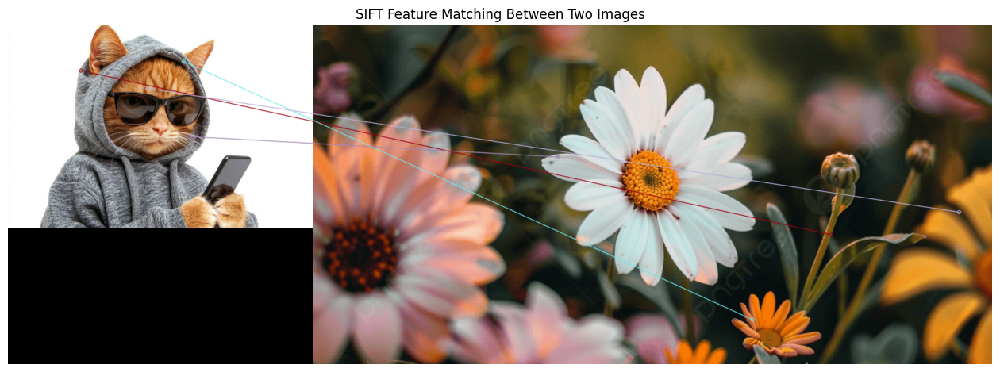

In [6]:
# Q2 - Upload TWO images
import io
uploaded = files.upload()

image_paths = []
images = []

for filename in uploaded.keys():
    with open(filename, 'wb') as f:
        f.write(uploaded[filename])
    print(f'Uploaded file: {filename}')

    img = cv2.imread(filename)
    if img is not None:
        image_paths.append(filename)
        images.append(img)

if len(images) < 2:
    raise ValueError("Please upload at least two valid images.")

image1, image2 = images[:2]

gray1 = cv2.cvtColor(image1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(image2, cv2.COLOR_BGR2GRAY)

sift = cv2.SIFT_create()
keypoints1, descriptors1 = sift.detectAndCompute(gray1, None)
keypoints2, descriptors2 = sift.detectAndCompute(gray2, None)

bf = cv2.BFMatcher()
matches = bf.knnMatch(descriptors1, descriptors2, k=2)

good_matches = []
for m, n in matches:
    if m.distance < 0.75 * n.distance:
        good_matches.append(m)

matched_image = cv2.drawMatches(
    image1, keypoints1,
    image2, keypoints2,
    good_matches[:80],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

print(f"Image 1: {image_paths[0]}")
print(f"Image 2: {image_paths[1]}")
print(f"Good SIFT correspondences: {len(good_matches)}")

plt.figure(figsize=(16, 8))
plt.imshow(cv2.cvtColor(matched_image, cv2.COLOR_BGR2RGB))
plt.title("SIFT Feature Matching Between Two Images")
plt.axis("off")
plt.show()


## Q3. Simple panorama stitcher using SIFT and homography estimation
The first two uploaded images should overlap in the same scene.

Saving panorama_input_image_2.png to panorama_input_image_2 (1).png
Saving panorama_input_image_1.png to panorama_input_image_1 (1).png
Uploaded file: panorama_input_image_2 (1).png
Uploaded file: panorama_input_image_1 (1).png
Good matches: 112
RANSAC inliers: 36


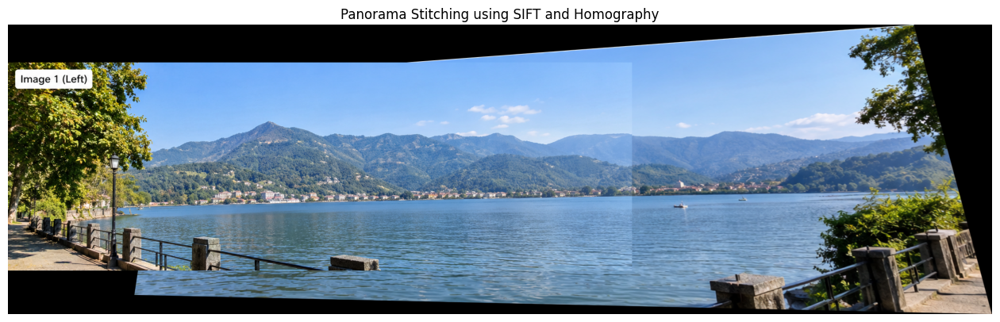

In [7]:
# Q3 - Upload TWO overlapping images
import io
uploaded = files.upload()

image_paths = []
images = []

for filename in uploaded.keys():
    with open(filename, 'wb') as f:
        f.write(uploaded[filename])
    print(f'Uploaded file: {filename}')

    img = cv2.imread(filename)
    if img is not None:
        image_paths.append(filename)
        images.append(img)

if len(images) < 2:
    raise ValueError("Please upload two overlapping images.")

left = images[0]
right = images[1]

sift = cv2.SIFT_create()

gray_left = cv2.cvtColor(left, cv2.COLOR_BGR2GRAY)
gray_right = cv2.cvtColor(right, cv2.COLOR_BGR2GRAY)

kp_left, des_left = sift.detectAndCompute(gray_left, None)
kp_right, des_right = sift.detectAndCompute(gray_right, None)

bf = cv2.BFMatcher()
raw_matches = bf.knnMatch(des_left, des_right, k=2)

good_matches = [
    m for m, n in raw_matches
    if m.distance < 0.75 * n.distance
]

if len(good_matches) < 4:
    raise ValueError("At least 4 good matches are required for homography.")

src_pts = np.float32(
    [kp_left[m.queryIdx].pt for m in good_matches]
).reshape(-1, 1, 2)

dst_pts = np.float32(
    [kp_right[m.trainIdx].pt for m in good_matches]
).reshape(-1, 1, 2)

H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)

if H is None:
    raise ValueError("Homography estimation failed.")

h1, w1 = left.shape[:2]
h2, w2 = right.shape[:2]

corners_left = np.float32(
    [[0, 0], [w1, 0], [w1, h1], [0, h1]]
).reshape(-1, 1, 2)

corners_right = np.float32(
    [[0, 0], [w2, 0], [w2, h2], [0, h2]]
).reshape(-1, 1, 2)

warped_corners = cv2.perspectiveTransform(corners_left, H)
all_corners = np.concatenate((warped_corners, corners_right), axis=0)

[xmin, ymin] = np.int32(all_corners.min(axis=0).ravel() - 0.5)
[xmax, ymax] = np.int32(all_corners.max(axis=0).ravel() + 0.5)

translation = np.array([
    [1, 0, -xmin],
    [0, 1, -ymin],
    [0, 0, 1]
], dtype=np.float64)

panorama = cv2.warpPerspective(
    left,
    translation @ H,
    (xmax - xmin, ymax - ymin)
)

panorama[-ymin:h2-ymin, -xmin:w2-xmin] = right

print(f"Good matches: {len(good_matches)}")
print(f"RANSAC inliers: {int(mask.sum()) if mask is not None else 0}")

plt.figure(figsize=(16, 8))
plt.imshow(cv2.cvtColor(panorama, cv2.COLOR_BGR2RGB))
plt.title("Panorama Stitching using SIFT and Homography")
plt.axis("off")
plt.show()


## Q4. Logo/object locator using SIFT feature matching
Upload a reference object/logo followed by a cluttered scene containing that object.

Saving ChatGPT Image Sep 28, 2026, 11_49_06 AM.png to ChatGPT Image Sep 28, 2026, 11_49_06 AM (1).png
Saving ChatGPT Image Sep 28, 2026, 11_47_41 AM.png to ChatGPT Image Sep 28, 2026, 11_47_41 AM (1).png
Uploaded file: ChatGPT Image Sep 28, 2026, 11_49_06 AM (1).png
Uploaded file: ChatGPT Image Sep 28, 2026, 11_47_41 AM (1).png
Good matches: 42
RANSAC inliers: 15
Object located: YES


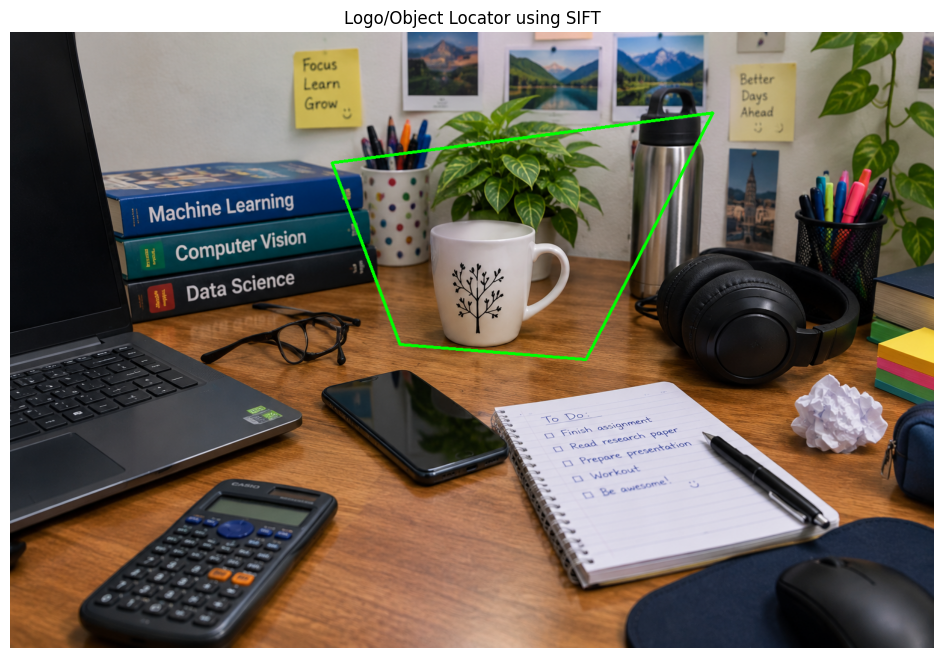

In [8]:
# Q4 - Upload TWO images:
# 1. Reference object/logo
# 2. Cluttered scene containing that object
import io
uploaded = files.upload()

image_paths = []
images = []

for filename in uploaded.keys():
    with open(filename, 'wb') as f:
        f.write(uploaded[filename])
    print(f'Uploaded file: {filename}')

    img = cv2.imread(filename)
    if img is not None:
        image_paths.append(filename)
        images.append(img)

if len(images) < 2:
    raise ValueError("Please upload the reference image first and the scene image second.")

reference = images[0]
scene = images[1]

sift = cv2.SIFT_create()
kp_ref, des_ref = sift.detectAndCompute(cv2.cvtColor(reference, cv2.COLOR_BGR2GRAY), None)
kp_scene, des_scene = sift.detectAndCompute(cv2.cvtColor(scene, cv2.COLOR_BGR2GRAY), None)

bf = cv2.BFMatcher()
raw_matches = bf.knnMatch(des_ref, des_scene, k=2)

good_matches = [
    m for m, n in raw_matches
    if m.distance < 0.72 * n.distance
]

output = scene.copy()
located = False
inliers = 0

if len(good_matches) >= 4:
    src_pts = np.float32(
        [kp_ref[m.queryIdx].pt for m in good_matches]
    ).reshape(-1, 1, 2)

    dst_pts = np.float32(
        [kp_scene[m.trainIdx].pt for m in good_matches]
    ).reshape(-1, 1, 2)

    H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)

    if H is not None:
        h, w = reference.shape[:2]
        corners = np.float32(
            [[0, 0], [w, 0], [w, h], [0, h]]
        ).reshape(-1, 1, 2)

        transformed_corners = cv2.perspectiveTransform(corners, H)

        cv2.polylines(
            output,
            [np.int32(transformed_corners)],
            True,
            (0, 255, 0),
            4
        )

        inliers = int(mask.sum()) if mask is not None else 0
        located = inliers >= 4

print(f"Good matches: {len(good_matches)}")
print(f"RANSAC inliers: {inliers}")
print("Object located:", "YES" if located else "NO / insufficient reliable matches")

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title("Logo/Object Locator using SIFT")
plt.axis("off")
plt.show()


In [9]:
import cv2

print("OpenCV version:", cv2.__version__)
print("OpenCV location:", cv2.__file__)
print("HOGDescriptor available:", hasattr(cv2, "HOGDescriptor"))

OpenCV version: 5.0.0
OpenCV location: /usr/local/lib/python3.13/dist-packages/cv2/__init__.py
HOGDescriptor available: True


In [10]:
!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python -q
!pip install opencv-contrib-python -q

## Q5. HOG-based pedestrian/person detector
Uses OpenCV's pretrained default HOG + SVM pedestrian detector.

Saving ChatGPT Image Sep 28, 2026, 12_01_04 PM.png to ChatGPT Image Sep 28, 2026, 12_01_04 PM (1).png
Uploaded file: ChatGPT Image Sep 28, 2026, 12_01_04 PM (1).png
Number of pedestrian detections: 8


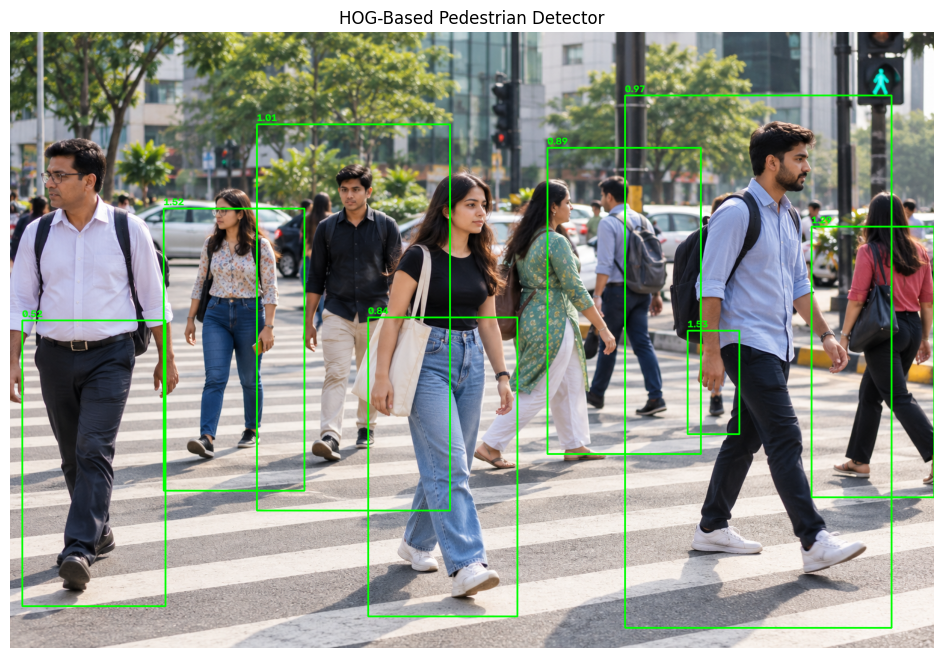

In [11]:
# Q5 - Upload one pedestrian/person image
import io
uploaded = files.upload()

for filename in uploaded.keys():
    with open(filename, 'wb') as f:
        f.write(uploaded[filename])
    print(f'Uploaded file: {filename}')
    image_path = filename
    break

image = cv2.imread(image_path)

if image is None:
    raise ValueError("Could not load the uploaded image.")

hog = cv2.HOGDescriptor()
hog.setSVMDetector(cv2.HOGDescriptor_getDefaultPeopleDetector())

(rects, weights) = hog.detectMultiScale(
    image,
    winStride=(8, 8),
    padding=(8, 8),
    scale=1.05
)

output = image.copy()

for (x, y, w, h), weight in zip(rects, weights):
    cv2.rectangle(output, (x, y), (x+w, y+h), (0, 255, 0), 2)
    cv2.putText(
        output,
        f"{float(weight):.2f}",
        (x, max(20, y-5)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.55,
        (0, 255, 0),
        2
    )

print(f"Number of pedestrian detections: {len(rects)}")

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title("HOG-Based Pedestrian Detector")
plt.axis("off")
plt.show()


In [12]:
hog_detector = cv2.HOGDescriptor()
hog_detector.setSVMDetector(
    cv2.HOGDescriptor_getDefaultPeopleDetector()
)

In [13]:
from skimage.feature import hog

## Q6. HOG visualizer
Overlay/visualize the gradient-orientation structure of the selected image.

Saving ChatGPT Image Sep 28, 2026, 12_01_04 PM.png to ChatGPT Image Sep 28, 2026, 12_01_04 PM (2).png
Uploaded file: ChatGPT Image Sep 28, 2026, 12_01_04 PM (2).png


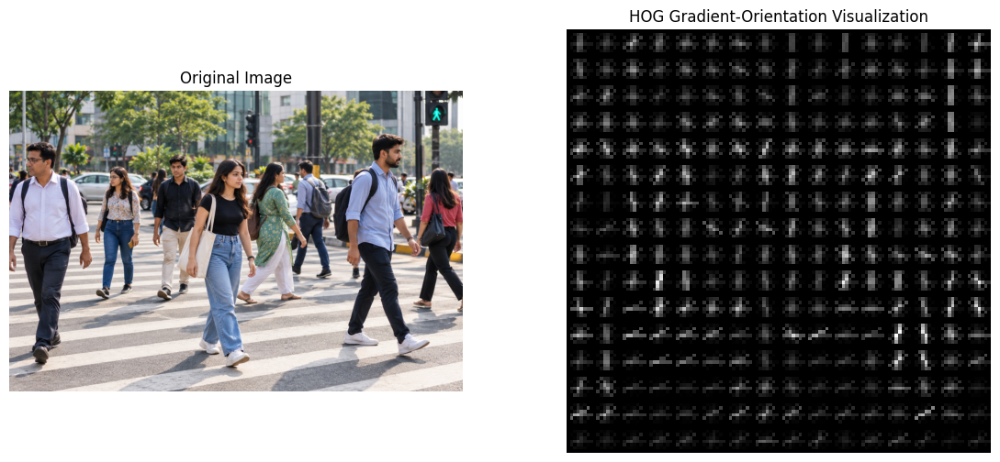

HOG feature vector length: 8100


In [14]:
# Q6 - Upload one image
import io
uploaded = files.upload()

for filename in uploaded.keys():
    with open(filename, 'wb') as f:
        f.write(uploaded[filename])
    print(f'Uploaded file: {filename}')
    image_path = filename
    break

image = cv2.imread(image_path)

if image is None:
    raise ValueError("Could not load the uploaded image.")

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
gray = cv2.resize(gray, (128, 128))

hog_features, hog_image = hog(
    gray,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    block_norm='L2-Hys',
    visualize=True,
    feature_vector=True
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(hog_image, cmap="gray")
axes[1].set_title("HOG Gradient-Orientation Visualization")
axes[1].axis("off")

plt.show()

print("HOG feature vector length:", len(hog_features))


## Q7. Duplicate / near-duplicate image detector using SIFT similarity scoring

Saving ChatGPT Image Sep 28, 2026, 06_43_36 PM (2).png to ChatGPT Image Sep 28, 2026, 06_43_36 PM (2).png
Saving ChatGPT Image Sep 28, 2026, 06_43_36 PM (1).png to ChatGPT Image Sep 28, 2026, 06_43_36 PM (1).png
Uploaded file: ChatGPT Image Sep 28, 2026, 06_43_36 PM (2).png
Uploaded file: ChatGPT Image Sep 28, 2026, 06_43_36 PM (1).png
Image 1: ChatGPT Image Sep 28, 2026, 06_43_36 PM (2).png
Image 2: ChatGPT Image Sep 28, 2026, 06_43_36 PM (1).png
Good matches: 157
SIFT similarity score: 2.57%
Result: Likely different images.


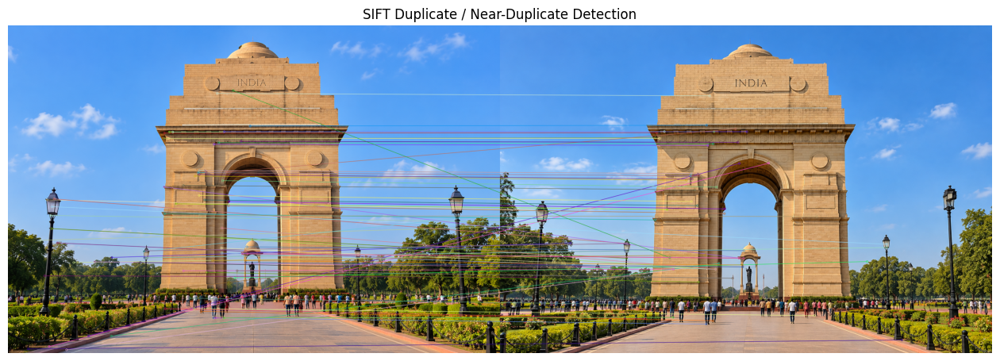

In [15]:
# Q7 - Upload TWO images
import io
uploaded = files.upload()

image_paths = []
images = []

for filename in uploaded.keys():
    with open(filename, 'wb') as f:
        f.write(uploaded[filename])
    print(f'Uploaded file: {filename}')

    img = cv2.imread(filename)
    if img is not None:
        image_paths.append(filename)
        images.append(img)

if len(images) < 2:
    raise ValueError("Please upload two images.")

image1, image2 = images[:2]

sift = cv2.SIFT_create()

kp1, des1 = sift.detectAndCompute(cv2.cvtColor(image1, cv2.COLOR_BGR2GRAY), None)
kp2, des2 = sift.detectAndCompute(cv2.cvtColor(image2, cv2.COLOR_BGR2GRAY), None)

bf = cv2.BFMatcher()
matches = bf.knnMatch(des1, des2, k=2)

good_matches = [
    m for m, n in matches
    if m.distance < 0.75 * n.distance
]

minimum_keypoints = max(1, min(len(kp1), len(kp2)))
similarity = 100 * len(good_matches) / minimum_keypoints

print(f"Image 1: {image_paths[0]}")
print(f"Image 2: {image_paths[1]}")
print(f"Good matches: {len(good_matches)}")
print(f"SIFT similarity score: {similarity:.2f}%")

if similarity >= 15:
    print("Result: Likely same/near-duplicate image or scene.")
elif similarity >= 5:
    print("Result: Possibly related; inspect the feature matches.")
else:
    print("Result: Likely different images.")

match_image = cv2.drawMatches(
    image1, kp1,
    image2, kp2,
    good_matches[:80],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(16, 8))
plt.imshow(cv2.cvtColor(match_image, cv2.COLOR_BGR2RGB))
plt.title("SIFT Duplicate / Near-Duplicate Detection")
plt.axis("off")
plt.show()


## Q8. Robustness / scale-invariance test for SIFT
SIFT keypoints are expected to remain useful under scale and other image transformations.

Saving ChatGPT Image Sep 28, 2026, 11_49_06 AM.png to ChatGPT Image Sep 28, 2026, 11_49_06 AM (2).png
Uploaded file: ChatGPT Image Sep 28, 2026, 11_49_06 AM (2).png
Original keypoints: 438
Scaled keypoints: 744
Rotated keypoints: 518
Original -> scaled good matches: 298
Original -> rotated good matches: 252


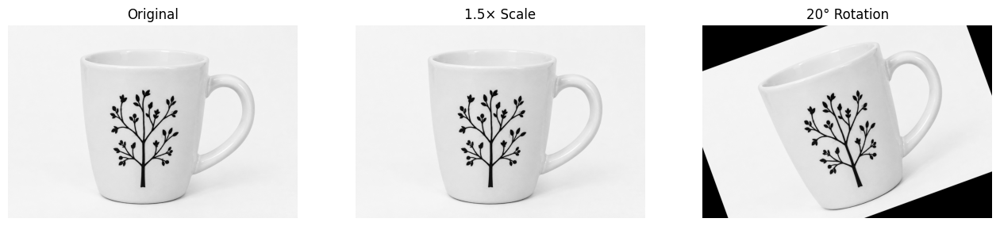

SIFT is designed to provide substantial robustness to scale and rotation changes.


In [16]:
# Q8 - Upload one image
import io
uploaded = files.upload()

for filename in uploaded.keys():
    with open(filename, 'wb') as f:
        f.write(uploaded[filename])
    print(f'Uploaded file: {filename}')
    image_path = filename
    break

image = cv2.imread(image_path)

if image is None:
    raise ValueError("Could not load the uploaded image.")

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Create transformed versions
scaled = cv2.resize(gray, None, fx=1.5, fy=1.5, interpolation=cv2.INTER_CUBIC)

center = (gray.shape[1] // 2, gray.shape[0] // 2)
rotation_matrix = cv2.getRotationMatrix2D(center, 20, 1.0)
rotated = cv2.warpAffine(
    gray,
    rotation_matrix,
    (gray.shape[1], gray.shape[0])
)

sift = cv2.SIFT_create()

kp_original, des_original = sift.detectAndCompute(gray, None)
kp_scaled, des_scaled = sift.detectAndCompute(scaled, None)
kp_rotated, des_rotated = sift.detectAndCompute(rotated, None)

bf = cv2.BFMatcher()

def good_match_count(desc1, desc2):
    if desc1 is None or desc2 is None:
        return 0
    raw = bf.knnMatch(desc1, desc2, k=2)
    return sum(1 for m, n in raw if m.distance < 0.75 * n.distance)

scale_matches = good_match_count(des_original, des_scaled)
rotation_matches = good_match_count(des_original, des_rotated)

print(f"Original keypoints: {len(kp_original)}")
print(f"Scaled keypoints: {len(kp_scaled)}")
print(f"Rotated keypoints: {len(kp_rotated)}")
print(f"Original -> scaled good matches: {scale_matches}")
print(f"Original -> rotated good matches: {rotation_matches}")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Original")
axes[1].imshow(scaled, cmap="gray")
axes[1].set_title("1.5× Scale")
axes[2].imshow(rotated, cmap="gray")
axes[2].set_title("20° Rotation")

for ax in axes:
    ax.axis("off")

plt.show()

print("SIFT is designed to provide substantial robustness to scale and rotation changes.")


## Q9. Simple SIFT image-retrieval system
Upload one query image followed by several database images. Images are ranked by the number of good SIFT matches.

Saving Screenshot 2026-09-28 185255.png to Screenshot 2026-09-28 185255.png
Saving Screenshot 2026-09-28 185333.png to Screenshot 2026-09-28 185333.png
Saving Screenshot 2026-09-28 185358.png to Screenshot 2026-09-28 185358.png
Saving Screenshot 2026-09-28 185420.png to Screenshot 2026-09-28 185420.png
Saving Screenshot 2026-09-28 185446.png to Screenshot 2026-09-28 185446.png
Saving Screenshot 2026-09-28 185527.png to Screenshot 2026-09-28 185527.png
Saving Screenshot 2026-09-28 185545.png to Screenshot 2026-09-28 185545.png
Uploaded file: Screenshot 2026-09-28 185255.png
Uploaded file: Screenshot 2026-09-28 185333.png
Uploaded file: Screenshot 2026-09-28 185358.png
Uploaded file: Screenshot 2026-09-28 185420.png
Uploaded file: Screenshot 2026-09-28 185446.png
Uploaded file: Screenshot 2026-09-28 185527.png
Uploaded file: Screenshot 2026-09-28 185545.png


,Image,Good_SIFT_Matches
1,Screenshot 2026-09-28 185333.png,91
2,Screenshot 2026-09-28 185545.png,19
3,Screenshot 2026-09-28 185358.png,18
4,Screenshot 2026-09-28 185527.png,10
5,Screenshot 2026-09-28 185446.png,7
6,Screenshot 2026-09-28 185420.png,5


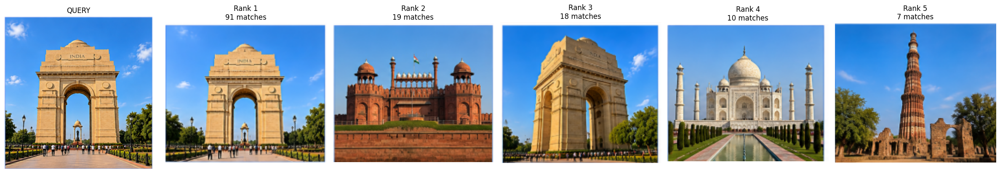

In [17]:
# Q9 - Upload QUERY image first, then DATABASE images
import io
uploaded = files.upload()

image_paths = []
images = []

for filename in uploaded.keys():
    with open(filename, 'wb') as f:
        f.write(uploaded[filename])
    print(f'Uploaded file: {filename}')

    img = cv2.imread(filename)
    if img is not None:
        image_paths.append(filename)
        images.append(img)

if len(images) < 2:
    raise ValueError(
        "Please upload at least 2 images: query image first, followed by database images."
    )

query = images[0]
database_images = images[1:]
database_names = image_paths[1:]

sift = cv2.SIFT_create()
kp_query, des_query = sift.detectAndCompute(
    cv2.cvtColor(query, cv2.COLOR_BGR2GRAY), None
)

results = []

for name, db_image in zip(database_names, database_images):
    kp_db, des_db = sift.detectAndCompute(
        cv2.cvtColor(db_image, cv2.COLOR_BGR2GRAY), None
    )

    if des_query is None or des_db is None:
        score = 0
    else:
        bf = cv2.BFMatcher()
        raw_matches = bf.knnMatch(des_query, des_db, k=2)
        score = sum(
            1 for m, n in raw_matches
            if m.distance < 0.75 * n.distance
        )

    results.append((name, score, db_image))

results.sort(key=lambda x: x[1], reverse=True)

ranking = pd.DataFrame(
    [(name, score) for name, score, _ in results],
    columns=["Image", "Good_SIFT_Matches"]
)
ranking.index = np.arange(1, len(ranking) + 1)

display(ranking)

top_n = min(5, len(results))

fig, axes = plt.subplots(1, top_n + 1, figsize=(4 * (top_n + 1), 4))

axes[0].imshow(cv2.cvtColor(query, cv2.COLOR_BGR2RGB))
axes[0].set_title("QUERY")
axes[0].axis("off")

for i, (name, score, db_image) in enumerate(results[:top_n], start=1):
    axes[i].imshow(cv2.cvtColor(db_image, cv2.COLOR_BGR2RGB))
    axes[i].set_title(f"Rank {i}\n{score} matches")
    axes[i].axis("off")

plt.tight_layout()
plt.show()


## Q10. Benchmark SIFT vs HOG descriptors on a basic object-recognition task

For a fair, simple experiment, upload **multiple labeled images**. The label is inferred from the filename:

- `cat_1.jpg`, `cat_2.jpg`, `cat_3.jpg`
- `dog_1.jpg`, `dog_2.jpg`, `dog_3.jpg`

The notebook extracts SIFT and HOG descriptors, trains a 1-NN classifier, and compares classification accuracy and feature-extraction time.

**Important:** SIFT descriptors have variable numbers of keypoints, so this benchmark converts them to a fixed-length descriptor using a compact Bag-of-Visual-Words representation. HOG is already fixed-length.



Successfully loaded 6 images.


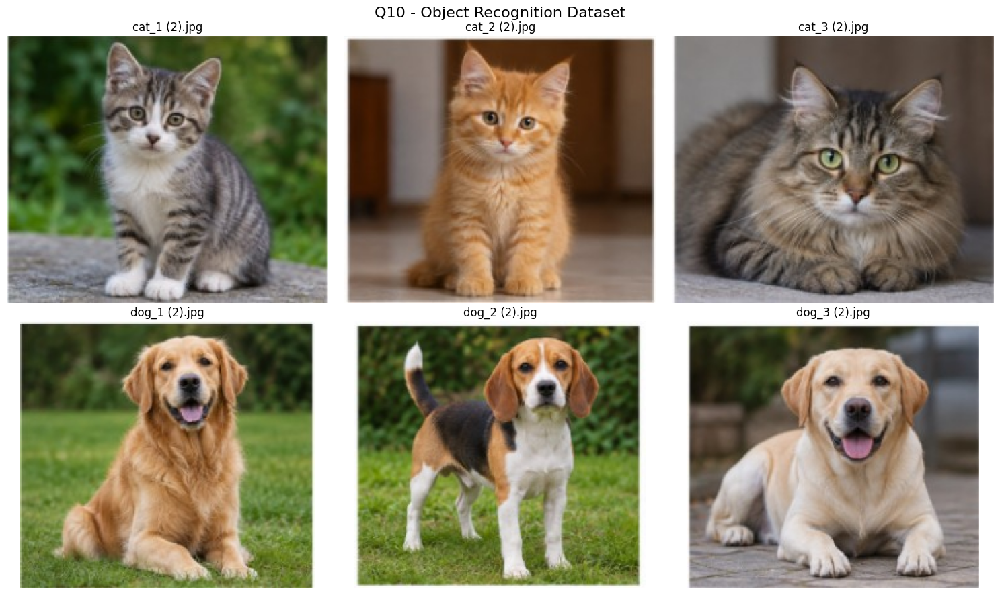

Uploaded file: cat_1 (2).jpg
Uploaded file: cat_2 (2).jpg
Uploaded file: cat_3 (2).jpg
Uploaded file: dog_1 (2).jpg
Uploaded file: dog_2 (2).jpg
Uploaded file: dog_3 (2).jpg


,Descriptor,Accuracy,Extraction_Time_sec,Feature_Dimension
0,SIFT,1.0,1.270632,8192
1,HOG,1.0,0.438733,8100


SIFT Classification Report
              precision    recall  f1-score   support

         cat       1.00      1.00      1.00         2
         dog       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4


HOG Classification Report
              precision    recall  f1-score   support

         cat       1.00      1.00      1.00         2
         dog       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



In [22]:
# Q10 - Display uploaded dataset

import cv2
import matplotlib.pyplot as plt
import os

# Reload images from the files that were uploaded
image_paths = []
images = []

for filename in uploaded.keys():

    image = cv2.imread(filename)

    if image is None:
        print(f"Could not load: {filename}")
        continue

    image_paths.append(filename)
    images.append(image)

print(f"\nSuccessfully loaded {len(images)} images.")

# Display images
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()

for i, (image, filename) in enumerate(zip(images, image_paths)):

    # Convert BGR -> RGB
    rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    axes[i].imshow(rgb_image)
    axes[i].set_title(filename)
    axes[i].axis("off")

# Hide unused axes
for i in range(len(images), len(axes)):
    axes[i].axis("off")

plt.suptitle(
    "Q10 - Object Recognition Dataset",
    fontsize=16
)

plt.tight_layout()
plt.show()

for filename in uploaded.keys():
    with open(filename, 'wb') as f:
        f.write(uploaded[filename])
    print(f'Uploaded file: {filename}')

    img = cv2.imread(filename)
    if img is not None:
        image_paths.append(filename)
        images.append(img)

if len(images) < 4:
    raise ValueError("Please upload a small labeled dataset with at least 4 images.")

def filename_label(filename):
    return Path(filename).stem.split("_")[0].lower()

labels = np.array([filename_label(name) for name in image_paths])

if len(set(labels)) < 2:
    raise ValueError(
        "Use at least two classes, e.g. cat_1.jpg and dog_1.jpg."
    )

# Fixed-length SIFT descriptor
def fixed_sift_descriptor(image, k=64):
    sift = cv2.SIFT_create()
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    keypoints, descriptors = sift.detectAndCompute(gray, None)

    output = np.zeros((k, 128), dtype=np.float32)

    if descriptors is None or len(descriptors) == 0:
        return output.flatten()

    # Keep the strongest keypoints
    order = np.argsort([-kp.response for kp in keypoints])
    selected = descriptors[order[:k]]

    output[:len(selected)] = selected
    return output.flatten()

# Extract SIFT features
start = time.perf_counter()
X_sift = np.vstack([
    fixed_sift_descriptor(image)
    for image in images
])
sift_time = time.perf_counter() - start

# Extract HOG features
start = time.perf_counter()
X_hog = np.vstack([
    hog_descriptor(image)
    for image in images
])
hog_time = time.perf_counter() - start

# =========================
# Train/Test Split
# =========================

Xtr_s, Xte_s, ytr_s, yte_s = train_test_split(
    X_sift,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

Xtr_h, Xte_h, ytr_h, yte_h = train_test_split(
    X_hog,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)


# =========================
# Simple 1-NN Classifier
# =========================
# We implement 1-NN directly instead of using sklearn's
# KNeighborsClassifier, avoiding the threadpoolctl warning.

def nearest_neighbor_predict(X_train, y_train, X_test):
    predictions = []

    for sample in X_test:
        distances = np.linalg.norm(X_train - sample, axis=1)
        nearest_index = np.argmin(distances)
        predictions.append(y_train[nearest_index])

    return np.array(predictions)


# SIFT prediction
pred_sift = nearest_neighbor_predict(
    Xtr_s,
    ytr_s,
    Xte_s
)

# HOG prediction
pred_hog = nearest_neighbor_predict(
    Xtr_h,
    ytr_h,
    Xte_h
)


# =========================
# Accuracy
# =========================

accuracy_sift = accuracy_score(
    yte_s,
    pred_sift
)

accuracy_hog = accuracy_score(
    yte_h,
    pred_hog
)


# =========================
# Results Table
# =========================

benchmark = pd.DataFrame({
    "Descriptor": ["SIFT", "HOG"],
    "Accuracy": [
        accuracy_sift,
        accuracy_hog
    ],
    "Extraction_Time_sec": [
        sift_time,
        hog_time
    ],
    "Feature_Dimension": [
        X_sift.shape[1],
        X_hog.shape[1]
    ]
})

display(benchmark)


# =========================
# Classification Reports
# =========================

print("SIFT Classification Report")
print(
    classification_report(
        yte_s,
        pred_sift,
        zero_division=0
    )
)

print("\nHOG Classification Report")
print(
    classification_report(
        yte_h,
        pred_hog,
        zero_division=0
    )
)